# Exploring Exposure Pipelines in StackGP

In [ ]:
from StackGP import *
from skimage.exposure import *
import imageio
import matplotlib.pyplot as plt

### Image operators and supporting functions

In [285]:
# bound a random value between min and max
def boundVal(val, minVal, maxVal):
    if val<minVal:
        return minVal
    elif val>maxVal:
        return maxVal
    else:
        return val
    
def equalize_histOverride(img,val):
    return equalize_hist(img, nbins=min(int(256*val),20))
equalize_histOverride.__repr__ = lambda : "equalize_hist"

def equalize_adapthistOverride(img,val1, val2, val3):
    return equalize_adapthist(img, clip_limit=val1%1, nbins=min(int(256*val2), 20), kernel_size=int(1+min(img.shape[:2])*val3))
equalize_adapthistOverride.__repr__ = lambda : "equalize_adapthist"

def rescale_intensityOverride(img, par):
    return rescale_intensity(img)
rescale_intensityOverride.__repr__ = lambda : "rescale_intensity"

def adjust_gammaOverride(img, gamma, gain):
    return adjust_gamma(img, gamma=boundVal(5*gamma,0.1,5), gain=boundVal(5*gain,0.1,5))
adjust_gammaOverride.__repr__ = lambda : "adjust_gamma"

def adjust_logOverride(img, gain):
    return adjust_log(img, gain=boundVal(5*gain,0.1,5))
adjust_logOverride.__repr__ = lambda : "adjust_log"

def adjust_sigmoidOverride(img, cutoff, gain):
    return adjust_sigmoid(img, cutoff=boundVal(cutoff%1,0.1,0.9), gain=boundVal(20*gain,1,20))
adjust_sigmoidOverride.__repr__ = lambda : "adjust_sigmoid"

In [286]:
 # removed [is_low_contrast], histogram, cumulative_distribution, match_histograms
imageOps=[adjust_gammaOverride, adjust_logOverride, adjust_sigmoidOverride, equalize_adapthistOverride, equalize_histOverride, rescale_intensityOverride]
expArities={"adjust_gamma":2, "adjust_log":1, "adjust_sigmoid":2, "equalize_adapthist":3, "equalize_hist":1, "rescale_intensity":1}
def ranVal():
    return random.random()
imgConst= [ranVal]

### Model evaluation functions

In [287]:
def see(img):
    plt.imshow(img)
    plt.axis('off')
    plt.show()
    return

# replace pixels greater than 1 with 1, less than 0 with 0
def clipImage(img):
    img[img>1]=1
    img[img<0]=0
    return img

def getImgArity(imgOp):
    return expArities[imgOp.__repr__()]

def evaluateGPImgModel(model,inputData): #Evaluates a model numerically
    response=evModImgHelper(model[1],model[0],[],inputData)[2]
    
    return response
def evModImgHelper(varStack,opStack,tempStack,img): #Recursive helper function for evaluateGPModel
    stack1=varStack
    stack2=opStack
    stack3=tempStack
    
    # check if all pixel values are same
    if np.all(img == img.flat[0]):
        return [stack3,stack2,stack1]
    if len(stack2)==0:
        return [stack3,stack2,stack1]
    op=stack2[0]
    stack2=stack2[1:]
    
    
        
    patt=getImgArity(op)
    while patt>len(stack3):
        stack3=[stack1[0]]+stack3
        stack1=stack1[1:]

    #print("stack3: ", stack3, " patt: ", patt, " data: ", np.mean(img), " op: ", op)
    try:
        temp=clipImage(op(img,*reverseList(stack3[:patt])))
    except TypeError:
        print("Type Error -- stack3: ", stack3, " patt: ", patt, " data: ", img, " op: ", op)
        temp=np.nan
    except OverflowError:
        temp=np.nan
    stack3=stack3[patt:]
    #stack3=[temp]+stack3
    
    if len(stack2)>0:
        stack1,stack2,stack3=evModImgHelper(stack1,stack2,stack3,temp)
        
    return [stack1,stack2,temp]

def modelImgArity(model): #Returns the total arity of a model
    return sum([getImgArity(i) for i in model[0]])

def generateRandomImgModel(ops,const,maxLength):  #Generates a random GP model
    prog = buildEmptyModel()                             #Generate an empty model with correct structure
    varChoices=const                           #All variable and constants choices
    prog[0]=np.array(np.random.choice(ops,random.randint(1,maxLength)),dtype=object) #Choose random operators
    countVars=modelImgArity(prog)    #Count how many variables/constants are needed
    prog[1]=np.random.choice(varChoices,countVars).tolist()       #Choose random variables/constants
    prog[1]=[i() if (callable(i) and i.__name__!='<lambda>' )else i for i in prog[1]] #If function then evaluate
    return prog
def initializeGPImgModels(ops=imageOps,const=defaultConst(),numberOfModels=100,maxLength=10): # generate random linear program
    prog=[[],[],[]]
    # prog stores [Operators, VarConst, QualityMetrics]
    
    models=[generateRandomImgModel(ops,const,maxLength) for i in range(numberOfModels)] #Generate models
    
    return models

In [249]:
[op for op in imageOps if getImgArity(op)==1 and op!='pop']

[<function __main__.adjust_logOverride(img, gain)>,
 <function __main__.equalize_histOverride(img, val)>,
 <function __main__.rescale_intensityOverride(img, par)>]

In [296]:
def imgmutate(model,variables,ops=defaultOps(),const=defaultConst(),maxLength=10):
    newModel=copy.deepcopy(model)
    newModel[0]=np.array(newModel[0],dtype=object).tolist()
    mutationType=random.randint(0,10)

    varChoices=[variableSelect(i) for i in range(variables)]+const
    opChoice=0
    varChoice=0
    
    tmp=0
    
    if mutationType==0: #single operator mutation
        opChoice=random.randint(0,len(newModel[0])-1)
        if len(newModel[0])>0:
            newModel[0][opChoice]=np.random.choice([i for i in ops] )
               
    elif mutationType==1: #single variable mutation
        varChoice=np.random.choice(varChoices)
        if callable(varChoice) and varChoice.__name__!='<lambda>':
            varChoice=varChoice()
        newModel[1][random.randint(0,len(newModel[1])-1)]=varChoice
    
    elif mutationType==2: #insertion mutation to top of stack
        opChoice=np.random.choice(ops)
        newModel[0]=[opChoice]+newModel[0]
        while modelImgArity(newModel)>len(newModel[1]):
            varChoice=np.random.choice(varChoices)
            if callable(varChoice) and varChoice.__name__!='<lambda>':
                varChoice=varChoice()
            newModel[1]=[varChoice]+newModel[1]
        
    elif mutationType==3: #deletion mutation from top of stack
        if len(newModel[0])>1:
            opChoice=random.randint(1,len(newModel[0])-1)
            newModel[0]=newModel[0][-opChoice:]
            newModel[1]=newModel[1][-modelImgArity([newModel[0]]):]
            
    elif mutationType==4: #insertion mutation to bottom of stack
        opChoice=np.random.choice([i for i in ops])
        newModel[0].append(opChoice)
        
    elif mutationType==5: #mutation via crossover with random model
        newModel=recombination2pt(newModel,generateRandomModel(variables,ops,const,maxLength))[0]
            
    elif mutationType==6: #single operator insertion mutation
        singleOps=[op for op in ops if getImgArity(op)==1 and op!='pop']
        #singleOps.append('pop')
        pos=random.randint(0,len(newModel[0])-1)
        newModel[0].insert(pos,np.random.choice(singleOps))

    elif mutationType>=7: #nudge numeric constant
        pos=get_numeric_indices(newModel[1])
        if(len(pos)>0): #If there are numeric constants
            pos=random.choice(pos)
            newModel[1][pos]=newModel[1][pos]+np.random.normal(-.05,.05) 
            
    if modelImgArity(newModel)<len(newModel[1]):
        newModel[1]=newModel[1][:modelImgArity(newModel)]
    elif modelImgArity(newModel)>len(newModel[1]):
        newModel[1]=newModel[1]+[np.random.choice(varChoices) for i in range(modelImgArity(newModel)-len(newModel[1]))]
    newModel[1]=[varChoice() if callable(varChoice) and varChoice.__name__!='<lambda>' else varChoice for varChoice in newModel[1]]         
    newModel[0]=np.array(newModel[0],dtype=object)
    return newModel


def imgevolve(inputData, responseData, generations=100, ops=copy.deepcopy(imageOps), const=imgConst, variableNames=[], mutationRate=79, crossoverRate=11, spawnRate=10, extinction=False,extinctionRate=10,elitismRate=50,popSize=300,maxComplexity=100,align=True,initialPop=[],timeLimit=300,capTime=False,tourneySize=5,tracking=False,liveTracking=False,liveTrackingInterval=1,modelEvaluationMetrics=[fitness,stackGPModelComplexity],dataSubsample=False,samplingMethod=randomSubsample,alternateObjectives=[],alternateObjFrequency=10,allowEarlyTermination=False,earlyTerminationThreshold=0):
    
    metrics=modelEvaluationMetrics

    fullInput,fullResponse=copy.deepcopy(inputData),copy.deepcopy(responseData)
    inData=copy.deepcopy(fullInput)
    resData=copy.deepcopy(fullResponse)
    models=initializeGPImgModels(ops,const,popSize)
    models=models+initialPop
    startTime=time.perf_counter()
    bestFits=[]
    if liveTracking:
        fig, ax = plt.subplots(figsize=(20,10))
        ckTime=time.perf_counter()
    for i in range(generations):
        if capTime and time.perf_counter()-startTime>timeLimit:
            break
        if len(alternateObjectives)>0 and (i+1)%alternateObjFrequency==0:
            metrics=modelEvaluationMetrics[:1]+alternateObjectives
        else:
            metrics=modelEvaluationMetrics
        if dataSubsample:
            inData,resData=samplingMethod(fullInput,fullResponse,generations=generations,generation=i)
        for mods in models:
            setModelQuality(mods,inData,resData,modelEvaluationMetrics=metrics)
        models=removeIndeterminateModels(models)
        if allowEarlyTermination and min([mods[2][0] for mods in models])<=earlyTerminationThreshold:
            print("Early termination at generation ", i)
            break
        if tracking or liveTracking:
            bestFits.append(min([mods[2][0] for mods in paretoTournament(models)]))
        if liveTracking and time.perf_counter()-ckTime>liveTrackingInterval:
            ax.clear()
            ax.plot(bestFits)
            ax.set_title(f"Best Model: {bestFits[-1]:.2f} at Generation {(i+1)}")
            ax.set_xlabel("Generations")
            ax.set_ylabel("Fitness")
            clear_output(wait=True) 
            display(fig)    
            #plt.show()        
            plt.close(fig)
            ckTime=time.perf_counter()        

        #paretoModels=paretoTournament(models)
        paretoModels=selectModels(models,elitismRate/100*popSize if elitismRate/100*popSize<len(models) else len(models))
        if extinction and i%extinctionRate==0 and i>0:
            models=initializeGPImgModels(ops,const,popSize)
            for mods in models:
                setModelQuality(mods,inData,resData,modelEvaluationMetrics=metrics)
        
        models=tournamentModelSelection(models,popSize,tourneySize)
        
        crossoverPairs=random.sample(models,round(crossoverRate/100*popSize))
        toMutate=random.sample(models,round(mutationRate/100*popSize))
        
        childModels=paretoModels
        
        for j in range(round(len(crossoverPairs)/2)-1):
            childModels=childModels+recombination2pt(crossoverPairs[j],crossoverPairs[j+round(len(crossoverPairs)/2)])
        
        for j in toMutate:
            childModels=childModels+[imgmutate(j,0,ops,const)]
        
        childModels=childModels+initializeGPImgModels(ops,const,round(spawnRate/100*popSize))
        
        childModels=deleteDuplicateModels(childModels)
        childModels=[model for model in childModels if stackGPModelComplexity(model)<maxComplexity]
        
        #for mods in childModels:
        #    setModelQuality(mods,inData,resData,modelEvaluationMetrics=modelEvaluationMetrics)
        #childModels=removeIndeterminateModels(childModels)
        
        if len(childModels)<popSize:
            childModels=childModels+initializeGPImgModels(ops,const,popSize-len(childModels))
        
        models=copy.deepcopy(childModels)
        
    
    for mods in models:
        setModelQuality(mods,fullInput,fullResponse,modelEvaluationMetrics=modelEvaluationMetrics+alternateObjectives)
    #models=[trimModel(mod) for mod in models]
    models=deleteDuplicateModels(models)
    models=removeIndeterminateModels(models)
    models=sortModels(models)
    #if align:
    #    models=[alignGPModel(mods,fullInput,fullResponse) for mods in models]
    
    if tracking:
        bestFits.append(min([mods[2][0] for mods in paretoTournament(models)])) 
        plt.figure()
        plt.plot(bestFits)
        plt.title("Fitness over Time")
        plt.xlabel("Generations")
        plt.ylabel("Fitness")
        plt.show()
    
    return models


/var/folders/tn/s_jbjrf525zd165vpvwykqk40000gn/T/ipykernel_92949/1943360064.py:1: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread('Dude.jpeg')


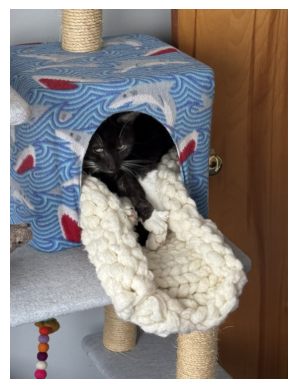

In [21]:
img = imageio.imread('Dude.jpeg')
# convert to float image
img=img.astype(float)/255.0
see(img)

[array([<function adjust_sigmoidOverride at 0x12099d4e0>,
       <function adjust_logOverride at 0x12099da80>,
       <function adjust_logOverride at 0x12099da80>,
       <function adjust_sigmoidOverride at 0x12099d4e0>], dtype=object), [0.3174089490307821, 0.8900431186334175, 0.8844709622686483, 0.31352349076807184, 0.49516112880787144, 0.44768084822212284], []]


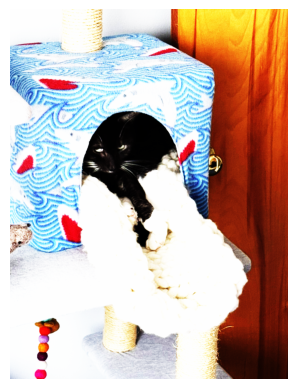

In [304]:
mm=generateRandomImgModel(imageOps,[ranVal],10)
print(mm)
# display before and after side by side
see(evaluateGPImgModel(mm, img))


In [289]:
def sampleFitFunc(model,img1, img2):
    try:
        diff=np.mean(np.abs(img2-evaluateGPImgModel(model,img1)))
    except:
        diff=np.inf
    return diff

def stackGPModelImgTimeComplexity(model,img1, img2, *args):
    start = time.perf_counter()
    try:
        diff=np.mean(np.abs(img2-evaluateGPImgModel(model,img1)))
    except:
        diff=np.inf
    end = time.perf_counter()
    return end-start

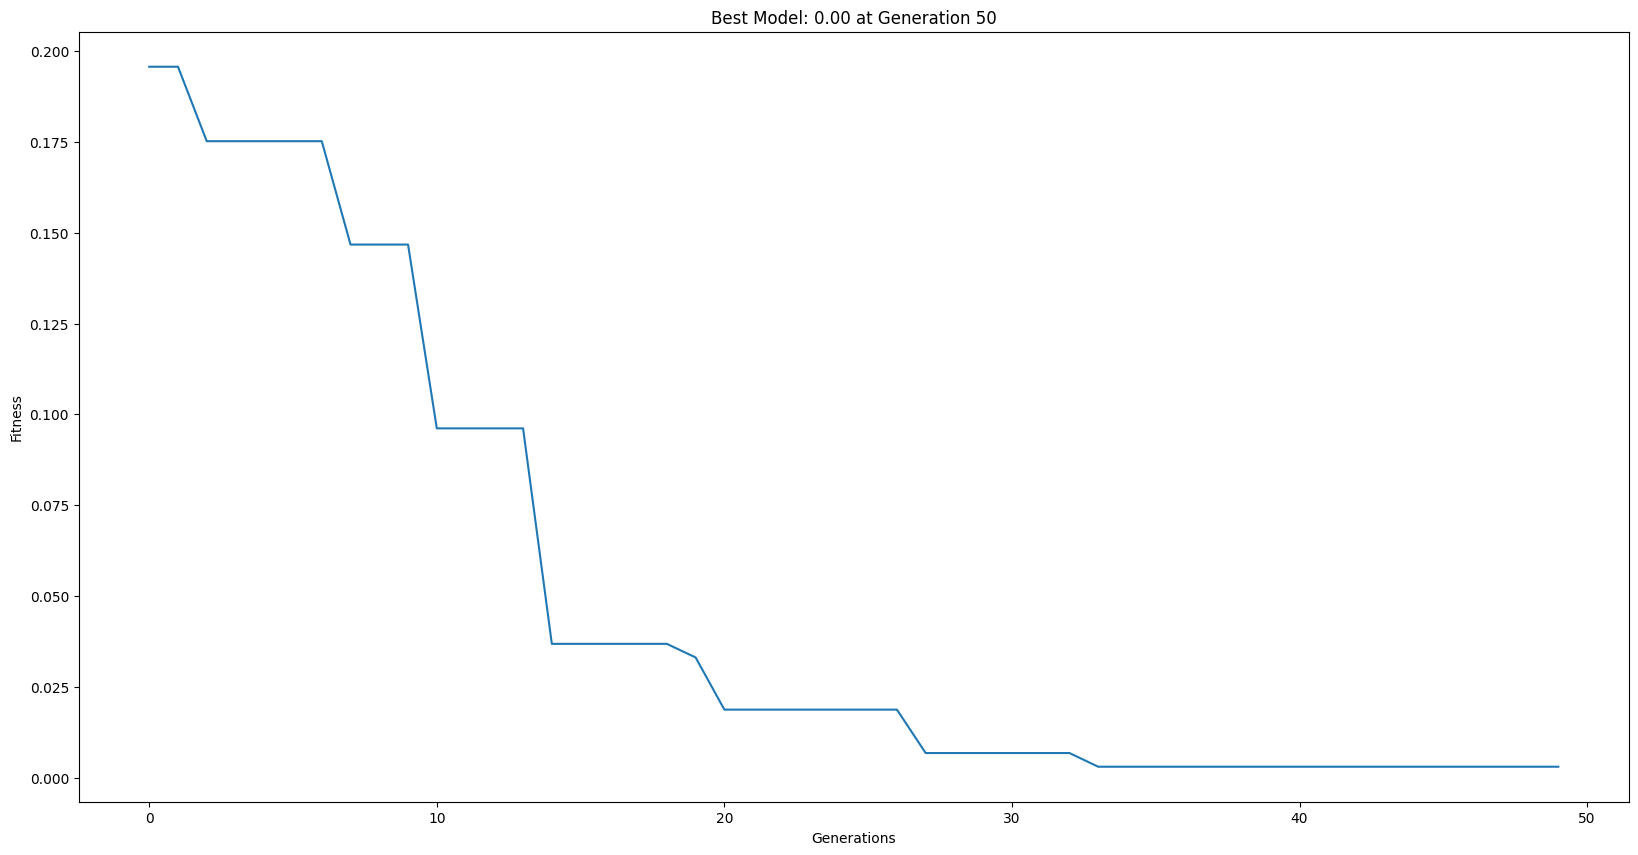

In [305]:
models=imgevolve(img,evaluateGPImgModel(mm,img),modelEvaluationMetrics=[sampleFitFunc,stackGPModelImgTimeComplexity],liveTracking=True,liveTrackingInterval=0,popSize=10,tourneySize=3,generations=50,initialPop=[],elitismRate=5)

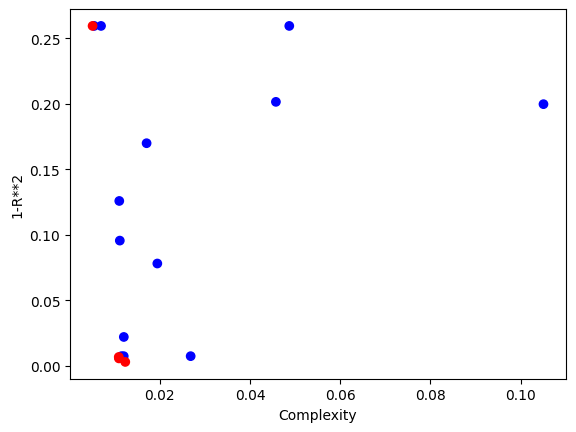

In [306]:
plotModels(models)

In [307]:
mm

[array([<function adjust_sigmoidOverride at 0x12099d4e0>,
        <function adjust_logOverride at 0x12099da80>,
        <function adjust_logOverride at 0x12099da80>,
        <function adjust_sigmoidOverride at 0x12099d4e0>], dtype=object),
 [0.3174089490307821,
  0.8900431186334175,
  0.8844709622686483,
  0.31352349076807184,
  0.49516112880787144,
  0.44768084822212284],
 []]

In [308]:
models[0]

[array([<function adjust_sigmoidOverride at 0x12099d4e0>], dtype=object),
 [0.3167016312726549, 0.9188579133488328],
 [np.float64(0.003014863947564244), 0.012324041977990419]]

In [309]:
sampleFitFunc(imgmutate(models[0],0,ops=copy.deepcopy(imageOps),const=defaultConst()),evaluateGPImgModel(mm,img),img)

np.float64(0.3386499820583991)

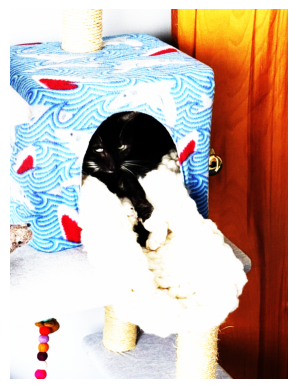

In [310]:
see(evaluateGPImgModel(models[0],img))

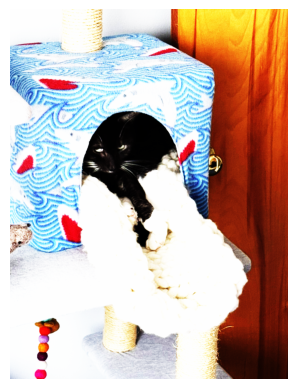

In [311]:
see(evaluateGPImgModel(mm, img))